# Train

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

tf.keras.utils.set_random_seed(42)

# ค้นหา Dataset ที่ Add Input ไว้ใน Kaggle
candidates = list(
    Path("/kaggle/input").glob("*/DIV2K_Restoration")
)

if not candidates:
    candidates = [
        p for p in Path("/kaggle/input").rglob("DIV2K_Restoration")
        if p.is_dir()
    ]

assert candidates, "ไม่พบ DIV2K_Restoration ใน /kaggle/input"

DATA_DIR = candidates[0]

OUTPUT_DIR = Path("/kaggle/working/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_DIR)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


Dataset: /kaggle/input/datasets/tomyumkung/datatatata/DIV2K_Restoration
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
BATCH_SIZE = 32
IMG_SIZE = 128

CATEGORIES = ["noise", "blur", "noise_blur"]

def make_dataset(split, categories=CATEGORIES, shuffle=False):
    input_paths = []
    target_paths = []

    clean_dir = DATA_DIR / split / "clean"

    for category in categories:
        degraded_dir = DATA_DIR / split / category

        files = sorted(degraded_dir.glob("*.png"))
        assert files, f"No images: {degraded_dir}"

        for path in files:
            target = clean_dir / path.name

            if not target.exists():
                raise FileNotFoundError(target)

            input_paths.append(str(path))
            target_paths.append(str(target))

    ds = tf.data.Dataset.from_tensor_slices(
        (input_paths, target_paths)
    )

    if shuffle:
        ds = ds.shuffle(
            len(input_paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_pair(x_path, y_path):
        def read_png(path):
            image = tf.io.decode_png(
                tf.io.read_file(path),
                channels=3
            )
            image = tf.image.convert_image_dtype(
                image, tf.float32
            )
            image = tf.ensure_shape(
                image, [IMG_SIZE, IMG_SIZE, 3]
            )
            return image

        return read_png(x_path), read_png(y_path)

    ds = ds.map(
        load_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("valid")
test_ds = make_dataset("test")

for x, y in train_ds.take(1):
    print("Input:", x.shape)
    print("Target:", y.shape)
    print("Range:", float(tf.reduce_min(x)),
          float(tf.reduce_max(x)))


I0000 00:00:1792448095.489324      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792448095.493539      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Input: (32, 128, 128, 3)
Target: (32, 128, 128, 3)
Range: 0.0 1.0


# เเก้ตรงนี้ model

In [3]:

from tensorflow.keras import layers, Model

# MIRNet-v2 (ขนาดเล็ก) สำหรับภาพ 128x128
# ตั้งค่าไม่ให้หนักเกิน: base_filters=24, num_mrb=2 (3 scales: 128 / 64 / 32)


def contextual_block(x, filters):
    # Residual Contextual Block: conv + depthwise conv + global context attention
    shortcut = x

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.DepthwiseConv2D(3, padding="same", depthwise_initializer="he_normal")(x)
    x = layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal")(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    ctx = layers.GlobalAveragePooling2D(keepdims=True)(x)
    ctx = layers.Conv2D(max(filters // 8, 4), 1, kernel_initializer="he_normal")(ctx)
    ctx = layers.LeakyReLU(negative_slope=0.2)(ctx)
    ctx = layers.Conv2D(filters, 1, activation="sigmoid")(ctx)
    x = layers.Multiply()([x, ctx])

    x = layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal")(x)
    return layers.Add()([shortcut, x])


def skff_block(features, filters):
    # Selective Kernel Feature Fusion: รวมหลาย scale ด้วย attention (softmax ข้าม scale)
    n = len(features)

    u = layers.Add()(features)
    s = layers.GlobalAveragePooling2D(keepdims=True)(u)
    z = layers.Conv2D(max(filters // 8, 4), 1, kernel_initializer="he_normal")(s)
    z = layers.LeakyReLU(negative_slope=0.2)(z)

    v = layers.Concatenate(axis=1)([
        layers.Conv2D(filters, 1)(z) for _ in range(n)
    ])                                      # (B, n, 1, C)
    attn = layers.Softmax(axis=1)(v)

    out = []
    for i in range(n):
        w_i = layers.Cropping2D(((i, n - 1 - i), (0, 0)))(attn)   # (B, 1, 1, C)
        out.append(layers.Multiply()([features[i], w_i]))
    return layers.Add()(out)


def down(x, filters, times=1):
    for _ in range(times):
        x = layers.Conv2D(filters, 3, strides=2, padding="same", kernel_initializer="he_normal")(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)
    return x


def up(x, filters, factor=2):
    x = layers.UpSampling2D(factor, interpolation="bilinear")(x)
    return layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal")(x)


def mrb_block(x, f):
    # Multi-scale Residual Block: 3 scales แลกข้อมูลกันด้วย SKFF
    shortcut = x
    f1, f2, f3 = f, f * 2, f * 4

    s1 = contextual_block(x, f1)                      # 128x128
    s2 = contextual_block(down(x, f2), f2)            # 64x64
    s3 = contextual_block(down(x, f3, times=2), f3)   # 32x32

    s1 = contextual_block(skff_block([s1, up(s2, f1)], f1), f1)
    s2 = contextual_block(skff_block([down(s1, f2), s2, up(s3, f2)], f2), f2)
    s3 = contextual_block(skff_block([down(s2, f3), s3], f3), f3)

    fused = skff_block([s1, up(s2, f1, 2), up(s3, f1, 4)], f1)
    out = layers.Conv2D(f1, 3, padding="same", kernel_initializer="he_normal")(fused)
    return layers.Add()([shortcut, out])


def build_mirnet_v2(input_shape=(128, 128, 3), base_filters=24, num_mrb=2):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(base_filters, 3, padding="same", kernel_initializer="he_normal")(inputs)
    shallow = x

    for _ in range(num_mrb):
        x = mrb_block(x, base_filters)

    x = layers.Conv2D(base_filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.Add()([shallow, x])

    # เรียนรู้ส่วนต่าง (residual) แล้วบวกกลับเข้า input -> เริ่มต้นได้ผลเท่ากับภาพ input
    # ไม่ใช้ ReLU(max_value=1) ที่ output เพราะทำให้ gradient ตายได้ (ตอนประเมินมี clip 0-1 อยู่แล้ว)
    residual = layers.Conv2D(3, 3, padding="same", kernel_initializer="zeros")(x)
    outputs = layers.Add()([inputs, residual])

    return Model(inputs, outputs, name="MIRNet_v2")


# ชื่อเดิมให้ cell เทรนด้านล่างเรียกใช้ได้โดยไม่ต้องแก้
def build_unet():
    return build_mirnet_v2(input_shape=(128, 128, 3), base_filters=24, num_mrb=2)


model = build_unet()
model.summary()


Model: "MIRNet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        672 │ input_layer[0][0] │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     10,416 │ conv2d[0][0]      │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 64, 64,    │          0 │ conv2d_6[0][0]    │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     20,784 │ leaky_re_lu_3[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      5,208 │ conv2d[0][0]      │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_1  │ (None, 64, 64,    │        480 │ leaky_re_lu_4[0]… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │      2,352 │ depthwise_conv2d… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 128, 128,  │        240 │ leaky_re_lu[0][0] │
│ (DepthwiseConv2D)   │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 64, 64,    │          0 │ conv2d_8[0][0]    │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │        600 │ depthwise_conv2d… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 48)  │          0 │ leaky_re_lu_5[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 128, 128,  │          0 │ conv2d_2[0][0]    │
│ (LeakyReLU)         │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 1, 1, 6)   │        294 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 24)  │          0 │ leaky_re_lu_1[0]… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 933,695 (3.56 MB)

 Trainable params: 933,695 (3.56 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

strategy = tf.distribute.MirroredStrategy()
print("Number of GPUs:", strategy.num_replicas_in_sync)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of GPUs: 2


In [5]:

EPOCHS = 30

with strategy.scope():
    model = build_unet()

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mae",
        metrics=[
            tf.keras.metrics.MeanSquaredError(name="mse")
        ]
    )

model.summary()

checkpoint_path = OUTPUT_DIR / "best_restoration_unet.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model:", checkpoint_path)


Model: "MIRNet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_111 (Conv2D) │ (None, 128, 128,  │        672 │ input_layer_1[0]… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_117 (Conv2D) │ (None, 64, 64,    │     10,416 │ conv2d_111[0][0]  │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_57      │ (None, 64, 64,    │          0 │ conv2d_117[0][0]  │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_118 (Conv2D) │ (None, 64, 64,    │     20,784 │ leaky_re_lu_57[0… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_58      │ (None, 64, 64,    │          0 │ conv2d_118[0][0]  │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_112 (Conv2D) │ (None, 128, 128,  │      5,208 │ conv2d_111[0][0]  │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_13 │ (None, 64, 64,    │        480 │ leaky_re_lu_58[0… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_54      │ (None, 128, 128,  │          0 │ conv2d_112[0][0]  │
│ (LeakyReLU)         │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_119 (Conv2D) │ (None, 64, 64,    │      2,352 │ depthwise_conv2d… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_12 │ (None, 128, 128,  │        240 │ leaky_re_lu_54[0… │
│ (DepthwiseConv2D)   │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_59      │ (None, 64, 64,    │          0 │ conv2d_119[0][0]  │
│ (LeakyReLU)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_113 (Conv2D) │ (None, 128, 128,  │        600 │ depthwise_conv2d… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 48)  │          0 │ leaky_re_lu_59[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_55      │ (None, 128, 128,  │          0 │ conv2d_113[0][0]  │
│ (LeakyReLU)         │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_120 (Conv2D) │ (None, 1, 1, 6)   │        294 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 24)  │          0 │ leaky_re_lu_55[0… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 933,695 (3.56 MB)

 Trainable params: 933,695 (3.56 MB)

 Non-trainable params: 0 (0.00 B)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

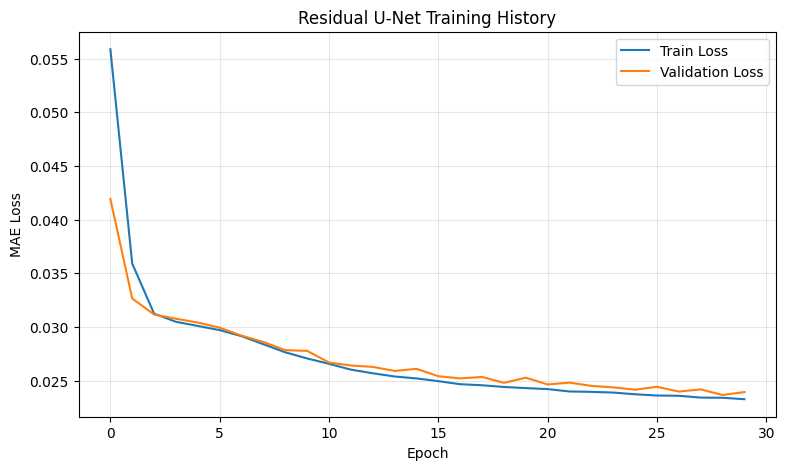

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE Loss")
plt.title("Residual U-Net Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [7]:

model = tf.keras.models.load_model(
    str(checkpoint_path)
)

results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    psnr_scores = []
    ssim_scores = []

    for x, y in ds:
        pred = model(x, training=False)
        pred = tf.clip_by_value(pred, 0.0, 1.0)

        psnr = tf.image.psnr(
            y, pred, max_val=1.0
        )
        ssim = tf.image.ssim(
            y, pred, max_val=1.0
        )

        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    results[category] = {
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

for category, scores in results.items():
    print(
        f"{category:12s} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}"
    )


noise        | PSNR: 33.11 dB | SSIM: 0.8988
blur         | PSNR: 32.52 dB | SSIM: 0.8401
noise_blur   | PSNR: 29.15 dB | SSIM: 0.7541


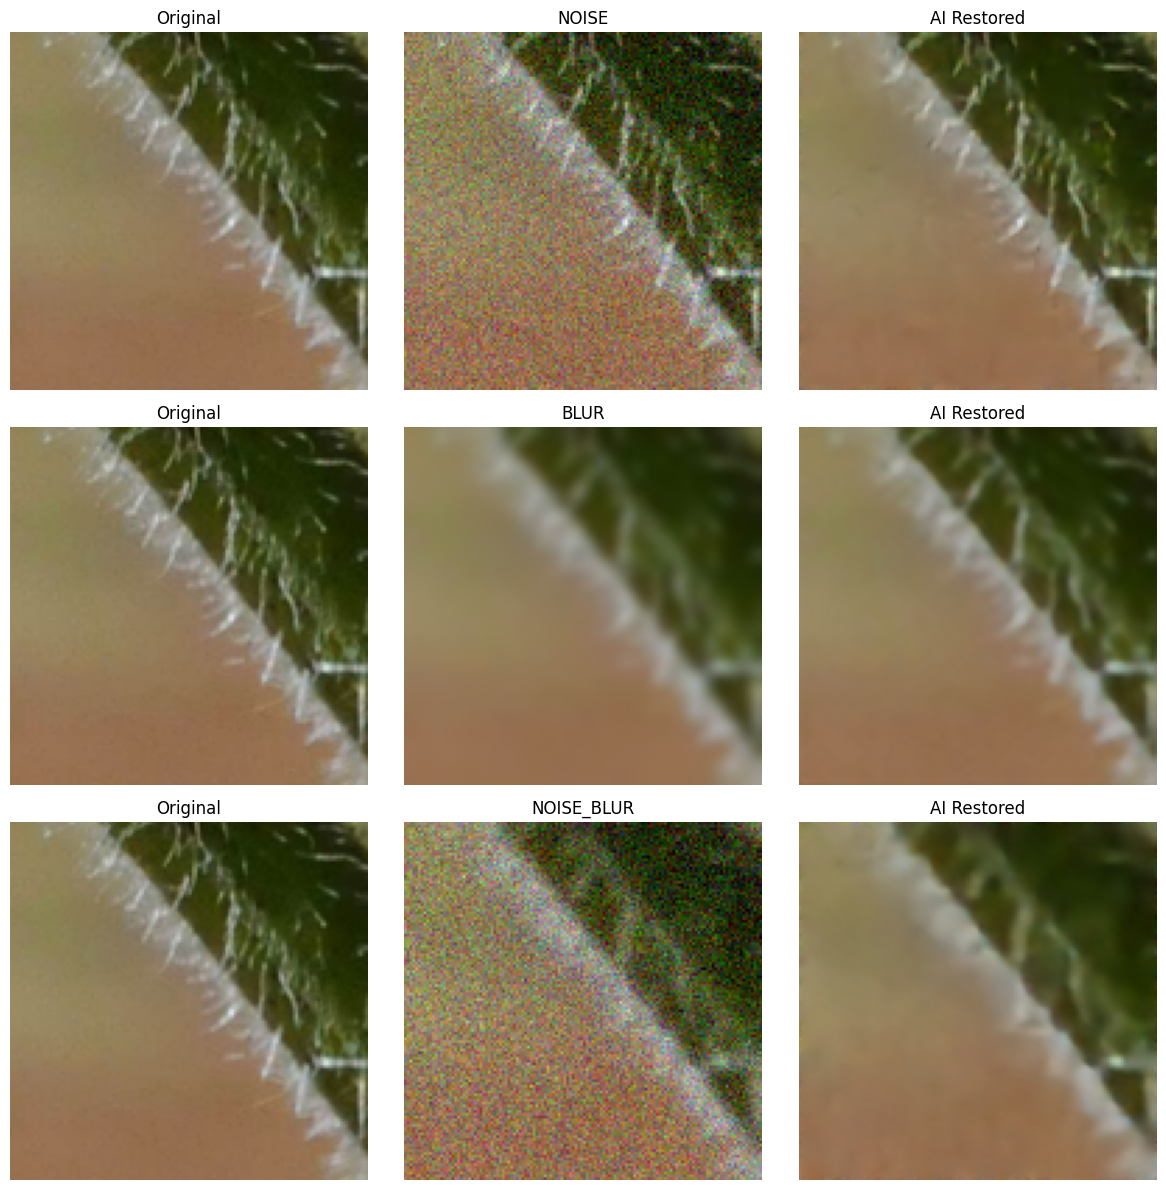

In [8]:
fig, axes = plt.subplots(
    3, 3, figsize=(12, 12)
)

for row, category in enumerate(CATEGORIES):
    ds = make_dataset(
        "test",
        categories=[category]
    )

    x, y = next(iter(ds))

    restored = model(
        x[:1], training=False
    )[0].numpy()

    images = [
        y[0].numpy(),
        x[0].numpy(),
        restored
    ]

    titles = [
        "Original",
        category.upper(),
        "AI Restored"
    ]

    for col, (img, title) in enumerate(zip(images, titles)):
        axes[row, col].imshow(
            np.clip(img, 0, 1)
        )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/restoration_results.png",
    dpi=200
)

plt.show()


In [9]:
model.save_weights("model.weights.h5")

In [10]:
model = tf.keras.models.load_model(
    str(checkpoint_path)
)

results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    mae_scores = []
    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    for x, y in ds:
        pred = model(x, training=False)
        pred = tf.clip_by_value(pred, 0.0, 1.0)

        # เฉลี่ยแกนความสูง ความกว้าง และช่องสี ได้หนึ่งค่าต่อภาพ
        error = y - pred

        mae = tf.reduce_mean(
            tf.abs(error), axis=[1, 2, 3]
        )
        mse = tf.reduce_mean(
            tf.square(error), axis=[1, 2, 3]
        )

        psnr = tf.image.psnr(
            y, pred, max_val=1.0
        )
        ssim = tf.image.ssim(
            y, pred, max_val=1.0
        )

        mae_scores.extend(mae.numpy())
        mse_scores.extend(mse.numpy())
        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    results[category] = {
        "MAE": float(np.mean(mae_scores)),
        "MSE": float(np.mean(mse_scores)),
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

for category, scores in results.items():
    print(
        f"{category:12s} | "
        f"MAE: {scores['MAE']:.6f} | "
        f"MSE: {scores['MSE']:.6f} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}"
    )

noise        | MAE: 0.018417 | MSE: 0.000714 | PSNR: 33.11 dB | SSIM: 0.8988
blur         | MAE: 0.023337 | MSE: 0.002140 | PSNR: 32.52 dB | SSIM: 0.8401
noise_blur   | MAE: 0.031044 | MSE: 0.002973 | PSNR: 29.15 dB | SSIM: 0.7541
